# Model 3: Custom CNN for Woodpecker and Great Tit Classification

## Dataset Characteristics

**Data Size:**
- Very small dataset: 20-30 training samples per class.
- Self-collected data rather of Great spotted woodpecker and Great tit.

**Data Collection & Preprocessing:**
- Audio files recorded in natural environments.
- Minimal preprocessing: volume normalization (maxed volume) using Audacity.
- No augmentation applied to original recordings.

## Data Preprocessing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import librosa
from glob import glob
import IPython.display as ipd
from PIL import Image

In [2]:
audio_files = glob('./data/wavfiles_woodpecker_great_tit/train/great_spotted_woodpecker/*.wav')
print(f"Total audio files found: {len(audio_files)}")

Total audio files found: 26


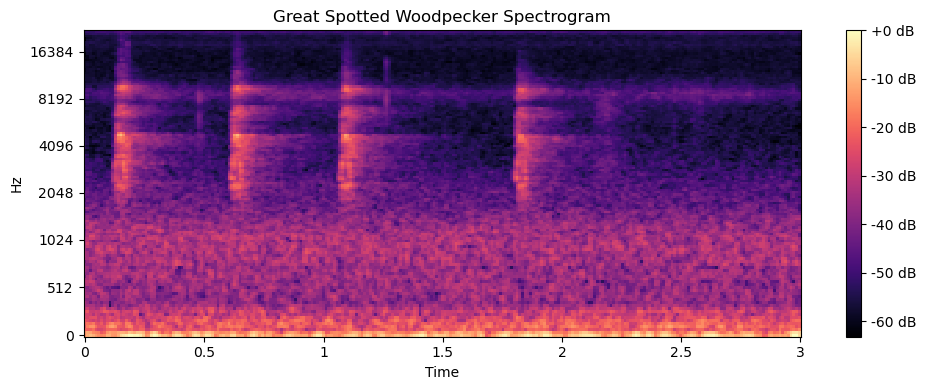

In [3]:
#create spectogram for an audio file
def plot_spectrogram(audio_file):
    #load audio file
    y, sr = librosa.load(audio_file, sr=None)

    #create spectrogram
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)
    return ipd.Audio(audio_file), S_dB, sr

#get sample audio and its spectrogram
audio_file = audio_files[10]
audio, mel_spec, sr = plot_spectrogram(audio_file)
plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spec, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Great Spotted Woodpecker Spectrogram")
plt.tight_layout()
plt.show()
audio

In [13]:
# convert mel spectrogram to a resized RGB image
def mel_to_images(S_db, img_size=(128, 128)):
    # Normalize to [0, 1]
    S_norm = (S_db - S_db.min()) / (S_db.max() - S_db.min())

    # Convert to PIL image
    img = Image.fromarray((S_norm * 255).astype(np.uint8))

    # Resize
    img = img.resize(img_size, resample=Image.BILINEAR)

    # Convert to RGB
    img = img.convert("RGB")

    return np.array(img).astype(np.float32) / 255.0

print(mel_to_images(mel_spec).shape)

(128, 128, 3)


In [15]:
# Set image size
img_size = (128, 128)

from pathlib import Path
base_path = Path("../Final_project/data/wavfiles_woodpecker_great_tit")
train_path = base_path / "train"
test_path = base_path / "test"

# Get class names and build file lists
class_names = sorted([d.name for d in train_path.iterdir() if d.is_dir()])
class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print(f"Classes found: {class_names}")

# Load and convert all wav files
X_train = []
y_train = []
X_test = []
y_test = []


Classes found: ['great_spotted_woodpecker', 'great_tit']


In [17]:
# Training data
print("Loading training data...")
for class_name in class_names:
    class_dir = train_path / class_name
    wav_files = list(class_dir.glob("*.wav"))
    print(f"  {class_name}: {len(wav_files)} files")
    
    for wav_file in wav_files:
        try:
            _, mel_spec, _ = plot_spectrogram(str(wav_file))  # Extract mel_spec (2nd return value)
            spec_img = mel_to_images(mel_spec, img_size)
            X_train.append(spec_img)
            y_train.append(class_to_idx[class_name])
        except Exception as e:
            print(f"    Error loading {wav_file.name}: {e}")

# Test data
print("Loading test data...")
for class_name in class_names:
    class_dir = test_path / class_name
    wav_files = list(class_dir.glob("*.wav"))
    print(f"  {class_name}: {len(wav_files)} files")
    
    for wav_file in wav_files:
        try:
            _, mel_spec, _ = plot_spectrogram(str(wav_file))
            spec_img = mel_to_images(mel_spec, img_size)
            X_test.append(spec_img)
            y_test.append(class_to_idx[class_name])
        except Exception as e:
            print(f"    Error loading {wav_file.name}: {e}")

Loading training data...
  great_spotted_woodpecker: 26 files
  great_tit: 27 files
Loading test data...
  great_spotted_woodpecker: 6 files
  great_tit: 6 files


In [18]:
# Convert to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")


Training set shape: (106, 128, 128, 3)
Test set shape: (12, 128, 128, 3)


In [19]:
# Split training into train/val (85/15 split with seed=42)
from sklearn.utils import shuffle

indices = np.arange(len(X_train))
indices = np.random.RandomState(42).permutation(indices)
split_idx = int(0.85 * len(X_train))

train_idx = indices[:split_idx]
val_idx = indices[split_idx:]

X_train_split = X_train[train_idx]
y_train_split = y_train[train_idx]
X_val = X_train[val_idx]
y_val = y_train[val_idx]

## Model


The model uses a 4-block CNN architecture with batch normalization and dropout:

- **4 Convolutional blocks** (32 → 64 → 128 → 256 filters)
- **Batch normalization** after each convolution for stability
- **Max pooling** (2×2) to reduce spatial dimensions
- **Dropout layers** (0.5, 0.3) to prevent overfitting
- **Dense layers** (256 → 128 → 2 output) with dropout

This architecture balances model capacity with the small dataset size. Early stopping monitors validation loss to prevent overfitting.

In [20]:
# Import libraries (add to existing imports if needed)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import time

# Convert labels to categorical (one-hot encoding)
num_classes = len(class_names)
train_y_cat = to_categorical(y_train_split, num_classes)
val_y_cat = to_categorical(y_val, num_classes)
test_y_cat = to_categorical(y_test, num_classes)

print(f"Train set: {X_train_split.shape}, {train_y_cat.shape}")
print(f"Validation set: {X_val.shape}, {val_y_cat.shape}")
print(f"Test set: {X_test.shape}, {test_y_cat.shape}")
print(f"Number of classes: {num_classes}")
print(f"Class names: {class_names}")

Train set: (90, 128, 128, 3), (90, 2)
Validation set: (16, 128, 128, 3), (16, 2)
Test set: (12, 128, 128, 3), (12, 2)
Number of classes: 2
Class names: ['great_spotted_woodpecker', 'great_tit']


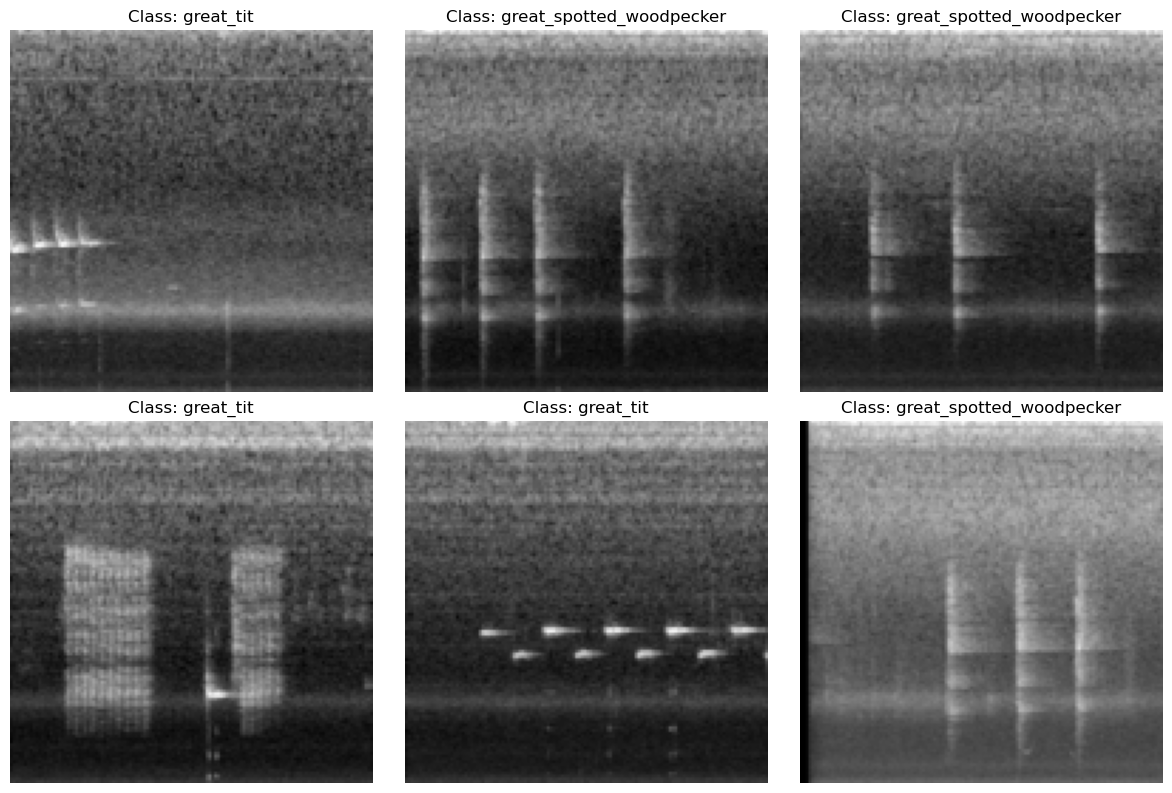

In [21]:
# Visualize sample spectrograms
plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_train_split[i])
    plt.title(f"Class: {class_names[y_train_split[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [23]:
# Define the Custom CNN model
model = models.Sequential([
    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Fourth convolutional block
    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and dense layers
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,783,042 (10.62 MB)

 Trainable params: 2,782,082 (10.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [24]:
# Define callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        'woodpecker_cnn_best_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

In [25]:
# Train the model
batch_size = 32
epochs = 30

start_time = time.time()

history = model.fit(
    X_train_split, train_y_cat,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(X_val, val_y_cat),
    callbacks=callbacks,
    verbose=1
)

training_time = time.time() - start_time
print(f"\nTraining completed in {training_time:.2f} seconds")

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 487ms/step - accuracy: 0.7778 - loss: 1.0269 - val_accuracy: 0.5625 - val_loss: 0.6912
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - accuracy: 0.7444 - loss: 1.6459 - val_accuracy: 0.3750 - val_loss: 0.6946
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 307ms/step - accuracy: 0.8111 - loss: 1.0080 - val_accuracy: 0.4375 - val_loss: 0.6954
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 287ms/step - accuracy: 0.9444 - loss: 0.4519 - val_accuracy: 0.4375 - val_loss: 0.7046
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 283ms/step - accuracy: 0.9556 - loss: 0.3085 - val_accuracy: 0.5000 - val_loss: 0.7435
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 286ms/step - accuracy: 0.9444 - loss: 0.1469 - val_accuracy: 0.5000 - val_loss: 0.7514

Training completed in 8.08 seconds


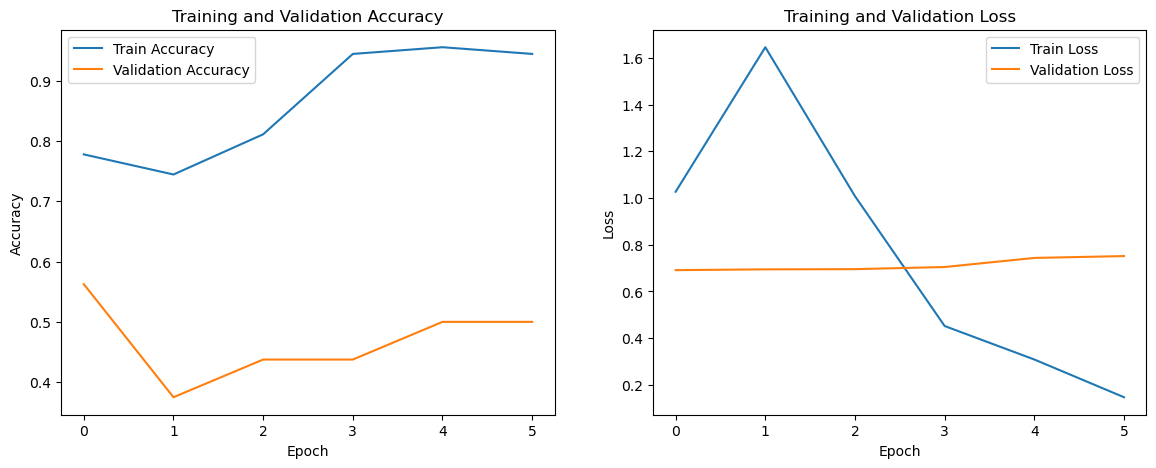

In [46]:
# Training and validation accuracy/loss plots
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

The Train accuracy plot shows that training accuracy steadily increased from approximately 77% to 95% over 5 epochs, while validation accuracy started at around 56% and stops at approximately 50%. This large gap of 45 % points between train and validation accuracy is a clear indicator of significant overfitting. The model memorizes the training patterns very well but fails to generalize to unseen data, which is a common problem when working with extremely limited datasets.

The Train loss plot shows that the training loss decreases smoothly from approximately 1.0 to 0.15, demonstrating excellent convergence on the training data. However, the validation loss remains relatively flat around 0.70 to 0.75 throughout the entire training process. This further confirms that the model is overfitting to the training data.

## Evaluation

In [26]:
# Evaluate on test set
test_loss, test_acc = model.evaluate(X_test, test_y_cat, verbose=2)
print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

1/1 - 0s - 41ms/step - accuracy: 0.5000 - loss: 0.6887
Test accuracy: 0.500
Test loss: 0.689


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


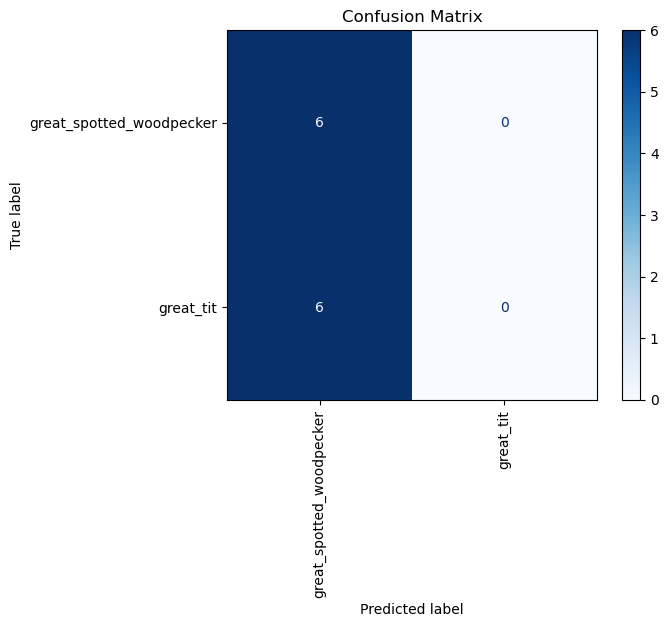

In [34]:
# Confusion Matrix
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
cm = confusion_matrix(y_test, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.title('Confusion Matrix')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


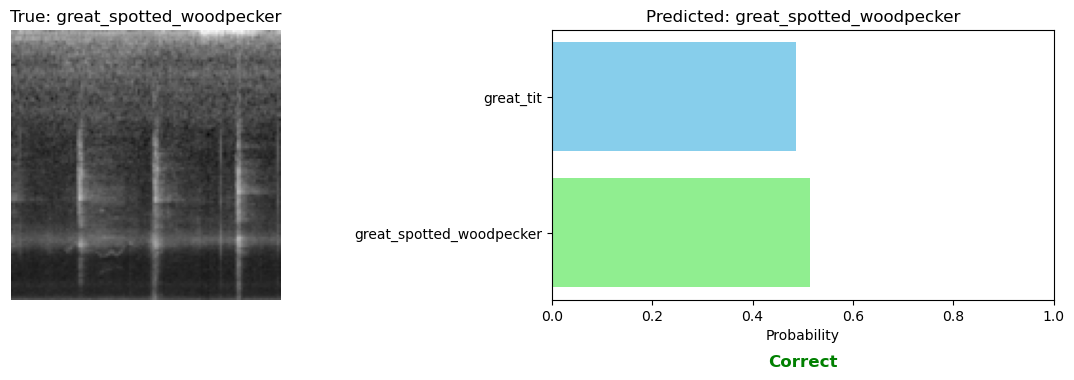

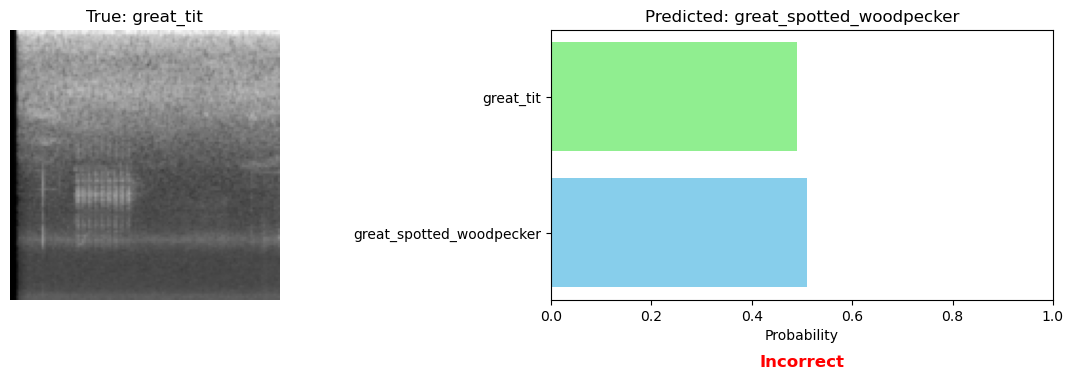

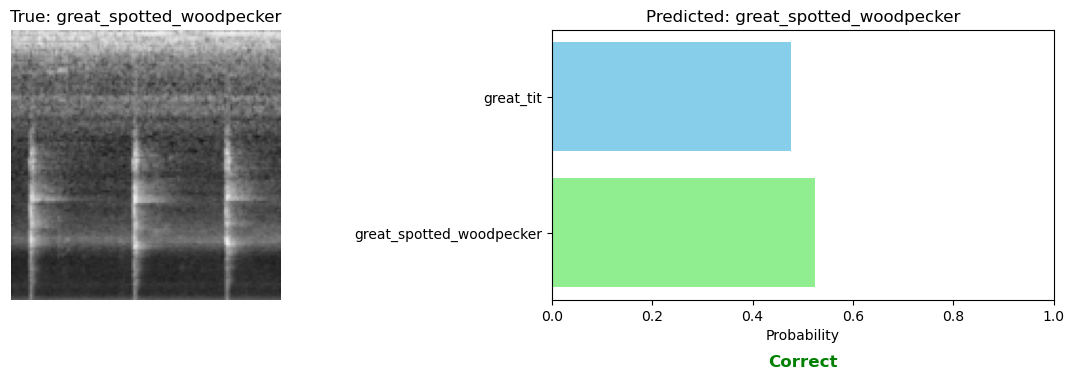

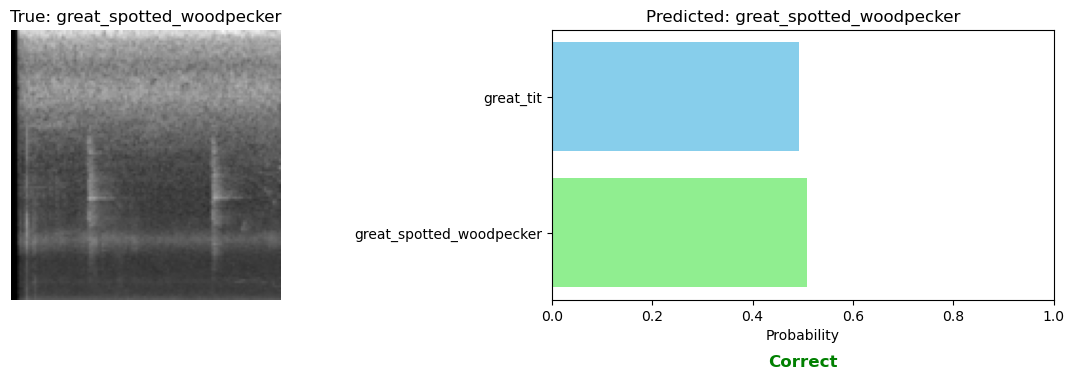

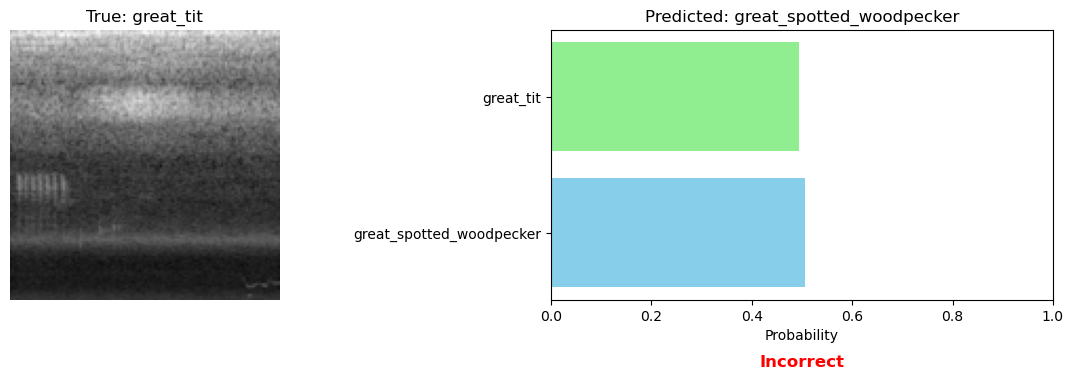

In [ ]:
import random

def plot_predictions(model, X_test, y_test, class_names):
    """
    Plot 5 random test samples with true labels and predicted probabilities
    """
    # Get predictions for all test data
    predictions = model.predict(X_test)
    predicted_labels = np.argmax(predictions, axis=1)
    
    # Pick 5 random samples
    num_samples = 5
    random_indices = random.sample(range(len(X_test)), num_samples)
    
    for i in random_indices:
        plt.figure(figsize=(12, 4))
        
        # LEFT: spectrogram image
        plt.subplot(1, 2, 1)
        plt.imshow(X_test[i])
        true_class = class_names[int(y_test[i])]
        plt.title(f"True: {true_class}")
        plt.axis("off")
        
        # RIGHT: bar chart of predicted probabilities
        plt.subplot(1, 2, 2)
        pred_prob = predictions[i]
        predicted_class = class_names[np.argmax(pred_prob)]
        
        # Colors: mark correct class green and the other one blue
        colors = [
            "lightgreen" if class_names[j] == true_class else "skyblue"
            for j in range(len(class_names))
        ]
        
        plt.barh(class_names, pred_prob, color=colors)
        plt.xlabel("Probability")
        plt.title(f"Predicted: {predicted_class}")
        plt.xlim([0, 1])
        
        # Add Correct/Incorrect label
        if predicted_class != true_class:
            plt.text(0.5, -0.25, "Incorrect", color="red", fontsize=12,
                    ha="center", transform=plt.gca().transAxes, weight='bold')
        else:
            plt.text(0.5, -0.25, "Correct", color="green", fontsize=12,
                    ha="center", transform=plt.gca().transAxes, weight='bold')
        
        plt.tight_layout()
        plt.show()

# Run the visualization
plot_predictions(model, X_test, y_test, class_names)

### Conclusion

The model achieved a test accuracy of 50% with a test loss of 0.689, which is much lower than the performance seen with the larger and higher-quality bird dataset used in the main bird species CNN models. This lower performance is expected because the model was trained with only 20–30 samples per class and with self-recorded audio that had very little preprocessing.

The confusion matrix shows an important imbalance in how the model performs on each class. While the great spotted woodpecker calls are classified correctly, the great tit samples are frequently misclassified as great spotted woodpeckers.

There are several reasons for this misclassification. Audio quality is certainly a contributing factor, as the self-collected recordings likely vary in background noise, signal strength, and microphone characteristics. Some great tit recordings may have been made at greater distances or in noisier environments, making them harder to recognize and easier to confuse with other species.

However, the fundamental difference lies in the vocal behavior and range of calls of these two species. The recorded great spotted woodpecker calls in both the training and test sets consist of a single, distinctive call type. This consistent signature call makes woodpeckers easier for the model to learn and recognize reliably. In contrast, great tits possess a much more varied vocal range with multiple different calls and songs, each with distinct sound characteristics. This vocal diversity within the species means that training on a limited number of great tit samples leaves the model unprepared for the full range of how great tits actually vocalize.

This finding highlights an important lesson in bird sound classification. Species with diverse range of calls require substantially more training data to learn all vocal variations. A single call type repeated across many recordings is far easier to memorize with limited data than a repertoire containing multiple call variants.